# Forelesning 10: Molekyldynamikk

<div class="bilde-hoyre" style="width:50%">

![Fjærmodell av en binding](bilder/fjaer_binding.png)

</div>

I dag skal vi

- skrive Newtons 2. lov som differensiallikninger
- modellere og simulere vibrasjonen i en kjemisk binding

Dette er ideen bak **molekyldynamikk**: Vi beregner kreftene på atomene og lar Newtons 2. lov flytte dem steg for steg.

In [4]:
import numpy as np
import matplotlib.pyplot as plt

## Del 1: En kloss på en fjær

**Hookes lov:** En fjær som er strukket en avstand $x$ fra likevekt, drar tilbake med kraften $F = -kx$. Jo stivere fjær, desto større **fjærkonstant** $k$.

</div>

### Newtons 2. lov som differensiallikninger

Kraften bestemmer akselerasjonen, $a = F/m$. Akselerasjonen er endringen i fart, og farten er endringen i posisjon. Vi går gjennom sammenhengen på tavla.

<div class="viktig">

To koblede differensiallikninger, akkurat som de koblede fartslovene forrige gang:

$$\frac{dv}{dt} = \frac{F}{m} \qquad\qquad \frac{dx}{dt} = v$$

Vi løser dem steg for steg:

$$v_{n+1} = v_n + a_n\,\Delta t \qquad\qquad x_{n+1} = x_n + v_{n+1}\,\Delta t$$

Kraft → akselerasjon → fart → posisjon. Legg merke til at vi bruker den **nye** farten når vi oppdaterer posisjonen (Euler-Cromer). Da bevares energien godt når noe svinger.

</div>

<div class="diskuter">

**Tipp først:** Vi drar klossen 1,0 m ut og slipper. Det er ingen friksjon. Hvordan ser bevegelsen ut?

</div>

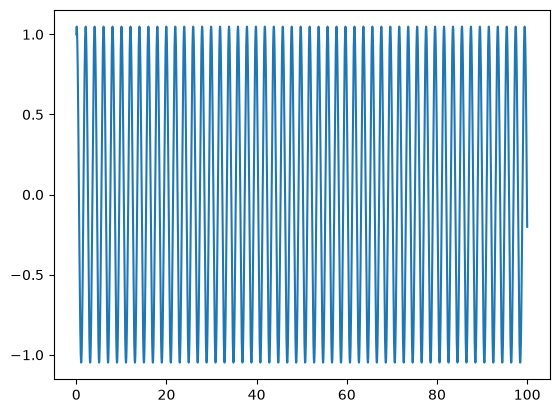

In [9]:
# Startbetingelser og konstanter
m = 1
k = 10
x0 = 1
v0 = 1

# Tidsparametre
t0 = 0
t_slutt = 100
dt = 1E-3
N = int((t_slutt - t0)/dt + 1)

# Arrayer
t = np.zeros(N)
v = np.zeros(N)
x = np.zeros(N)
t[0] = t0
v[0] = v0
x[0] = x0

# Integrasjonsløkke
for i in range(N - 1):
    F = -k*x[i] # Hookes lov
    a = F/m     # Newtons 2. lov
    # Eulers metode
    v[i+1] = v[i] + a*dt
    x[i+1] = x[i] + v[i+1]*dt
    # Oppdaterer tida 
    t[i+1] = t[i] + dt

plt.plot(t, x)
plt.show()

<div class="diskuter">

**Diskuter:** Hva skjer med svingningen hvis vi gjør fjæra stivere? Hva hvis klossen blir tyngre? Tipp først, og test.

</div>

## Del 2: En kjemisk binding som fjær

<div class="viktig">

I et toatomig molekyl er bindingen fjæra, og $k$ er **bindingsstyrken**. Begge atomene beveger seg, så vi bruker den **reduserte massen** i stedet for $m$:

$$\mu = \frac{m_1 m_2}{m_1 + m_2}$$

Da kan vi bruke **nøyaktig den samme koden**. $x$ er nå hvor mye bindingen er strukket i forhold til likevektslengden.

</div>

<div class="oppgave">

**Prøv selv:** Simuler vibrasjonen i HCl med $k = 516$ N/m. Fyll inn den reduserte massen. Massene er 1,008 u for H og 34,97 u for Cl. Legg deretter til DCl (D har massen 2,014 u) i samme figur.

</div>

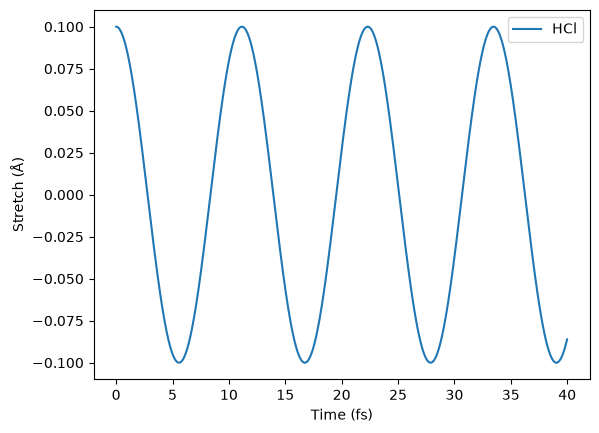

In [11]:
u = 1.66054e-27     # kg
k = 516             # N/m
dt = 1e-17          # s (0,01 femtosekund)
t = np.arange(0, 40e-15, dt)

m1 = 1.008*u # masse H
m2 = 34.97*u # masse U
mu = m1*m2/(m1 + m2)

x = np.zeros(len(t))
v = np.zeros(len(t))
x[0] = 1e-11        # strekker bindingen 0,1 Å

for n in range(len(t) - 1):
    a = -k * x[n] / mu
    v[n + 1] = v[n] + a * dt
    x[n + 1] = x[n] + v[n + 1] * dt

plt.plot(t * 1e15, x * 1e10, label="HCl")
plt.xlabel("Time (fs)")
plt.ylabel("Stretch (Å)")
plt.legend()
plt.show()

<div class="viktig">

Én svingning i HCl tar omtrent **11 femtosekunder**. Det gir frekvensen $\nu = 1/T \approx 9 \cdot 10^{13}$ Hz og bølgetallet $\tilde{\nu} = \nu/c \approx 3000$ cm⁻¹. Målt verdi i IR-spekteret er 2886 cm⁻¹, så den enkle fjærmodellen treffer godt.

En **stiv binding** (stor $k$) vibrerer raskt, og **tunge atomer** (stor $\mu$) vibrerer langsomt.

</div>

<div class="diskuter">

**Diskuter:** HCl og DCl har samme binding og samme $k$. Hvorfor vibrerer DCl langsommere? Gå tilbake til spørsmålet om C=O og C–O. Hva er forklaringen?

</div>

## Oppsummering

<div class="viktig">

1. **Kraft → akselerasjon → fart → posisjon:** Newtons 2. lov er to koblede differensiallikninger som vi løser steg for steg.
2. En kjemisk binding kan modelleres som en fjær. **Stivere binding** og **lettere atomer** gir høyere vibrasjonsfrekvens.
3. **Molekyldynamikk** bruker den samme oppskriften for tusenvis av atomer samtidig, med mer realistiske krefter.

</div>

__Oppgaver__:
1. Legg til friksjon i fjærsimuleringen, slik at kraften blir $F = -kx - bv$. Simuler med $b$ = 0,2, 1 og 10 kg/s. Beskriv de tre typene oppførsel.
2. Simuler CO-bindingen med $k = 1902$ N/m og massene 12,000 u og 15,995 u. Les av svingetiden fra plottet, og regn ut bølgetallet. Den målte verdien er 2143 cm⁻¹.
3. En C–H-binding absorberer ved omtrent 2900 cm⁻¹. Bruk $\tilde{\nu} = \dfrac{1}{2\pi c}\sqrt{\dfrac{k}{\mu}}$ til å finne fjærkonstanten. Hvor mye endres bølgetallet hvis H byttes med D?